# DataCo Smart Supply Chain — Late-Delivery Risk
## Notebook 2 — Model Training & Comparison

**IT3091 · Group 2026-AI-05 · Guided Data Track (Logistics & Supply Chain)**

| Member | IT Number | Role |
|---|---|---|
| Bolonne B.R.M. | IT24102050 | Framing + EDA |
| Kodagoda D.S. | IT24101613 | Preprocessing + baseline |
| Jayasekara C.D. | IT24103494 | Advanced models + tuning |
| Liyanage J.L.K.L. | IT24101927 | Evaluation + recommendation |

**Input:** `artifacts/processed_dataset.csv` produced by Notebook 1.
**Task:** binary classification · target `Late_delivery_risk` (1 = late).

### What the rubric asks for here

> *"Sensible baseline and **at least three alternatives**; choice of methods justified by
> **task, data, interpretability, and constraints**."* — criterion 5, 20 marks

> *"Appropriate metrics, train/test or cross-validation logic, leakage prevention, honest
> interpretation, and comparison **beyond accuracy**."* — criterion 6, 20 marks

Note the second half of criterion 5: a results table is not enough, every model needs a written
reason. Each model section below has one.

### Three rules carried over from Notebook 1

1. **The preprocessor goes INSIDE the Pipeline** — so it is re-fitted on each CV fold. Applying it
   once up front would fit the scaler and encoder on the validation folds too.
2. **The test split is opened once, at the end.** All tuning uses validation or CV on train.
3. **Never report accuracy alone** — 57% of orders are late, so "always late" scores 57% already.

### Expected result — set this before you start

Notebook 1 proved the ceiling is a property of the data, not of the method:

| Reference | Val ROC-AUC |
|---|---|
| Majority class | 0.5000 |
| `Shipping Mode` alone (4 columns) | 0.7387 |
| Logistic Regression, all 132 features | 0.7471 |

So **expect 0.75–0.79**. Tree models gain ~2 points over the linear baseline. Nobody reaches 0.90.

> **Any model above 0.95 means leakage, not success.**

---
## 0 · Setup

In [2]:
# SETUP: imports, seed and plot theme. Same RANDOM_STATE as Notebook 1 so every
# number in this notebook is reproducible and comparable with the preprocessing run.
import json, warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ART_DIR = Path("artifacts")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
C_MAGENTA, C_GREEN, C_VIOLET, C_RED = "#e87ba4", "#008300", "#4a3aa7", "#e34948"
SERIES = [C_BLUE, C_ORANGE, C_AQUA, C_VIOLET, C_MAGENTA, C_GREEN, C_YELLOW, C_RED]
SURFACE, INK, INK_2, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#8f8e88"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "font.family": "DejaVu Sans",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.titlecolor": INK, "axes.labelcolor": INK_2, "axes.labelsize": 9.5,
    "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e8e7e1",
    "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})

def finish(ax, title=None, subtitle=None, xlabel=None, ylabel=None, pct=False, hgrid=False):
    if hgrid:
        ax.grid(axis="x", color="#e8e7e1", linewidth=0.8); ax.grid(axis="y", visible=False)
    if title:
        ax.set_title(title, loc="left", pad=26 if subtitle else 12)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9,
                color=INK_MUTED, va="bottom", ha="left")
    ax.set_xlabel(xlabel or "", labelpad=8); ax.set_ylabel(ylabel or "", labelpad=8)
    if pct:
        (ax.xaxis if hgrid else ax.yaxis).set_major_formatter(PercentFormatter(1.0, decimals=0))
    return ax

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

pd.set_option("display.width", 200)
print(f"pandas {pd.__version__} | seed {RANDOM_STATE}")

pandas 3.0.6 | seed 42


In [3]:
# XGBoost is a separate package (not part of scikit-learn).
# WHY we guard the import: if it is missing the notebook must still run end to end,
# so we fall back to sklearn's HistGradientBoostingClassifier - the same algorithm
# family (histogram-based gradient boosting), just a different implementation.
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    import xgboost; print(f"xgboost {xgboost.__version__} available")
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False
    print("xgboost NOT installed -> falling back to HistGradientBoostingClassifier")
    print("to install:  py -m pip install xgboost")

xgboost 3.4.1 available


---
## 1 · Load the processed dataset

We read the single CSV Notebook 1 produced. It carries a `split` column, so the train /
validation / test partition is reproduced exactly rather than re-derived here.

In [4]:
# LOAD the processed dataset. One CSV holds all three splits, tagged by a 'split' column.
# WHY read this instead of re-doing the preprocessing: the split boundaries, the dropped
# columns and the feature list were all decided (and justified) in Notebook 1. Re-deriving
# them here would risk the two notebooks silently disagreeing.
data = pd.read_csv(ART_DIR / "processed_dataset.csv", parse_dates=["order date (DateOrders)"])
manifest = json.loads((ART_DIR / "manifest.json").read_text())

TARGET = manifest["target"]
CAT    = manifest["categorical_features"]
NUM    = manifest["numeric_features"]
FEATURES = CAT + NUM
META   = ["split"] + manifest["metadata_columns"]   # Order Id + order date: NOT features

print(f"rows {len(data):,}  columns {data.shape[1]}")
print(f"features: {len(FEATURES)}  ({len(CAT)} categorical + {len(NUM)} numeric)")
print()
print(data["split"].value_counts().reindex(["train", "val", "test"]).to_string())
data.head(3)

rows 172,765  columns 30
features: 26  (9 categorical + 17 numeric)

split
train    109871
val       29842
test      33052


,split,Order Id,order date (DateOrders),Late_delivery_risk,Type,Shipping Mode,Customer Segment,Customer Country,Customer State,Market,...,order_month,order_day,order_dayofweek,order_hour,order_quarter,order_weekofyear,is_weekend,is_month_end,is_quarter_end,is_afternoon
0,train,1,2015-01-01 00:00:00,0,CASH,Standard Class,Consumer,EE. UU.,NC,LATAM,...,1,1,3,0,1,1,0,0,0,0
1,train,2,2015-01-01 00:21:00,0,PAYMENT,Standard Class,Consumer,EE. UU.,IL,LATAM,...,1,1,3,0,1,1,0,0,0,0
2,train,2,2015-01-01 00:21:00,0,PAYMENT,Standard Class,Consumer,EE. UU.,IL,LATAM,...,1,1,3,0,1,1,0,0,0,0


In [5]:
# SPLIT BACK OUT using the 'split' column, then separate X from y.
# NOTE the metadata columns (split, Order Id, order date) are deliberately NOT in FEATURES.
# Order Id especially: it is an identifier, and letting a model see it would be leakage
# of a kind - the model could memorise which orders were late.
tr = data[data["split"] == "train"]
va = data[data["split"] == "val"]
te = data[data["split"] == "test"]

X_train, y_train = tr[FEATURES], tr[TARGET]
X_val,   y_val   = va[FEATURES], va[TARGET]
X_test,  y_test  = te[FEATURES], te[TARGET]

for nm, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"  {nm:<6s} {X.shape[0]:>7,} x {X.shape[1]}   late {y.mean():.2%}")

  train  109,871 x 26   late 57.36%
  val     29,842 x 26   late 57.09%
  test    33,052 x 26   late 57.25%


In [6]:
# VERIFY the hand-off before building anything on top of it.
# WHY assert rather than trust: if Notebook 1 is re-run with different settings, or an old
# CSV is lying around, these catch it immediately instead of producing a wrong model.
DT = manifest["metadata_columns"][1]
checks = [
    ("Splits are disjoint by Order Id",
     not (set(tr["Order Id"]) & set(va["Order Id"])) and
     not (set(tr["Order Id"]) & set(te["Order Id"]))),
    ("Splits are ordered in time", tr[DT].max() < va[DT].min() <= va[DT].max() < te[DT].min()),
    ("Rows sorted chronologically within each split",
     all(d[DT].is_monotonic_increasing for d in (tr, va, te))),
    ("No missing values in features", X_train.isna().sum().sum() == 0),
    ("No leakage column in the feature list",
     not any(c in FEATURES for c in ["Days for shipping (real)", "Delivery Status",
                                     "Order Status", "Days for shipment (scheduled)"])),
    ("Class balance consistent", max(abs(y_train.mean() - s.mean()) for s in (y_val, y_test)) < .02),
]
for label, ok in checks:
    print(f"  {'PASS' if ok else 'FAIL'}  {label}")
assert all(ok for _, ok in checks), "hand-off check failed - re-run Notebook 1"

  PASS  Splits are disjoint by Order Id
  PASS  Splits are ordered in time
  PASS  Rows sorted chronologically within each split
  PASS  No missing values in features
  PASS  No leakage column in the feature list
  PASS  Class balance consistent


---
## 2 · Why these models

The rubric marks the *justification*, not just the comparison. Each model is here to answer a
different question, and together they cover four distinct algorithm families.

| Model | Family | The question it answers | Interpretability |
|---|---|---|---|
| Majority class | — | What does doing nothing score? | n/a |
| `Shipping Mode` rule | — | Does ML beat a lookup table a manager could run in Excel? | total |
| **Logistic Regression** | **linear** | **baseline: how far does a simple additive model get?** | high — signed coefficients |
| Decision Tree | single tree | Does non-linearity help at all, in the simplest possible form? | high — readable rules |
| Random Forest | bagging ensemble | Does averaging many trees reduce variance enough to matter? | medium — importances |
| XGBoost | boosting ensemble | Does sequential error-correction beat averaging? | medium — importances |
| MLP (neural net) | neural | Does raw model capacity help? | low |

**Why Logistic Regression is the baseline** — it is interpretable, deterministic, needs no tuning
to be fair, and §9.3 of Notebook 1 showed there is no mode × market interaction, so a linear model
is not artificially handicapped here. That makes it a *fair* baseline rather than a strawman.

**Why the `Shipping Mode` rule is included** — this is the honest test. It scored 0.7387 in
Notebook 1 using four columns. If the full models cannot beat that meaningfully, the ML is
reproducing a lookup table with extra steps, and the report should say so.

**On class imbalance — a stated choice, not an omission.** The target is 57/43, a ratio of
1.35:1. No model below uses `class_weight="balanced"` and no resampling is applied, because at
this ratio reweighting mainly distorts the predicted probabilities (which §13 depends on) without
improving ranking. We handle the imbalance through *metric choice* and *threshold selection*
instead.

**Why MLP is included** — it is the only model here that can represent arbitrary interactions.
Given one feature carries nearly all the signal, we *expect* it to add nothing; confirming that
from a fourth independent direction is evidence for the ceiling, not a wasted run.

**Constraints that shaped the list** — 110k training rows and 132 encoded columns. KNN was
rejected (distance is near-meaningless across 115 binary one-hot columns, and it is slow at this
size); Naive Bayes was rejected (it assumes feature independence, which one-hot dummies of the
same feature violate by construction).

---
## 3 · The preprocessing pipeline and CV strategy

In [7]:
# REBUILD the preprocessor (identical spec to Notebook 1 section 10).
# WHY rebuild rather than load the fitted .joblib: inside cross-validation the preprocessor
# must be RE-FITTED on each training fold. A pre-fitted object would carry statistics from
# the full training set into every fold, which leaks across folds.
# We still load the saved one below purely to assert the two specs match.
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=20, sparse_output=False)),
])
preprocessor = ColumnTransformer(
    transformers=[("num", numeric_pipe, NUM), ("cat", categorical_pipe, CAT)],
    remainder="drop", verbose_feature_names_out=False,
)

# Sanity: the freshly built spec must produce the same width as Notebook 1 recorded.
n_cols = preprocessor.fit(X_train).transform(X_train.head(5)).shape[1]
assert n_cols == manifest["n_features_encoded"], \
    f"encoded width {n_cols} != manifest {manifest['n_features_encoded']}"
print(f"preprocessor rebuilt and verified: {len(FEATURES)} raw -> {n_cols} encoded columns")

preprocessor rebuilt and verified: 26 raw -> 132 encoded columns


In [8]:
# PIPELINE FACTORY - every model is wrapped the same way.
# This is the single most important line in the notebook: putting the preprocessor INSIDE
# the Pipeline means .fit() re-learns the medians / categories / scaling on whatever data
# it is handed, so each CV fold is preprocessed using only that fold's training part.
def make_pipeline(estimator):
    return Pipeline([("prep", clone(preprocessor)), ("clf", estimator)])


# CROSS-VALIDATION: TimeSeriesSplit, matching the chronological split from Notebook 1.
# WHY NOT plain KFold: one order spans up to 5 rows that share a label, so a random fold
# would put the answer on both sides. TimeSeriesSplit trains on the past and validates on
# the future, which also mirrors how the model would actually be deployed.
#
# BUT plain TimeSeriesSplit is not quite enough. It cuts at a ROW index, and an order's
# rows sit next to each other, so a boundary can land INSIDE an order - putting some of its
# line items in train and the rest in validation, label included. We measured it: 2 orders
# (4 rows) straddle a boundary. Tiny, but it is the exact leak we rejected KFold for, so we
# close it rather than wave it away.
class OrderAwareTimeSeriesSplit:
    """TimeSeriesSplit that never lets one order appear on both sides of a fold."""
    def __init__(self, n_splits=5):
        self.base = TimeSeriesSplit(n_splits=n_splits)
        self.n_splits = n_splits

    def split(self, X, y=None, groups=None):
        g = np.asarray(groups)
        for itr, iva in self.base.split(X):
            # drop any validation row whose order was already seen in training
            keep = ~np.isin(g[iva], g[itr])
            yield itr, iva[keep]

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits


CV = OrderAwareTimeSeriesSplit(n_splits=5)
GROUPS = tr["Order Id"].to_numpy()      # must be passed to every cross_val_score call

# Prove it worked.
leaks = sum(len(set(GROUPS[a]) & set(GROUPS[b])) for a, b in CV.split(X_train, groups=GROUPS))
print(f"OrderAwareTimeSeriesSplit(n_splits=5)  |  orders straddling a fold: {leaks}")
assert leaks == 0

OrderAwareTimeSeriesSplit(n_splits=5)  |  orders straddling a fold: 0


---
## 4 · Evaluation helpers

Defined once and reused for every model, so the comparison is apples-to-apples.

In [9]:
# METRICS. We report six, because accuracy alone is misleading at 57% base rate.
#   accuracy  - included only so it can be compared against the 57% floor
#   precision - of the orders we flag as late, how many really are?
#   recall    - of the orders that are late, how many do we catch?   <-- business priority
#   f1        - harmonic mean of the two
#   roc_auc   - ranking quality, threshold-free; the headline metric here
#   pr_auc    - average precision; more informative than ROC on imbalanced data
def evaluate(name, model, X, y, split="val", fit_seconds=None):
    pred  = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {"model": name, "split": split,
            "accuracy":  accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall":    recall_score(y, pred, zero_division=0),
            "f1":        f1_score(y, pred, zero_division=0),
            "roc_auc":   roc_auc_score(y, proba),
            "pr_auc":    average_precision_score(y, proba),
            "fit_s":     fit_seconds}

results, fitted, cv_scores = [], {}, {}

def train_and_record(name, estimator, cv=False):
    """Fit on train, score on validation, store the result. Optionally cross-validate."""
    pipe = make_pipeline(estimator)
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    secs = time.perf_counter() - t0

    row = evaluate(name, pipe, X_val, y_val, fit_seconds=secs)
    results.append(row); fitted[name] = pipe
    print(pd.DataFrame([row]).round(4).to_string(index=False))

    if cv:
        s = cross_val_score(pipe, X_train, y_train, cv=CV, groups=GROUPS,
                            scoring="roc_auc", n_jobs=-1)
        cv_scores[name] = s
        print(f"   5-fold CV ROC-AUC: {s.mean():.4f} +/- {s.std():.4f}   {np.round(s, 4)}")
    return pipe

---
## 5 · Reference point 1 — the majority-class floor

Not a model. It exists so every later number can be read against it.

In [10]:
# MAJORITY-CLASS BASELINE: always predict "late", the more common class.
# WHY it matters: it scores ~57% ACCURACY for free. Without this line on the table, a model
# reporting 70% accuracy looks good; against it, you can see it is only +13 points.
# Its ROC-AUC is exactly 0.50 because it cannot rank orders at all - which is the point:
# accuracy and ranking quality are different things.
train_and_record("0 · Majority class", DummyClassifier(strategy="most_frequent"))

             model split  accuracy  precision  recall     f1  roc_auc  pr_auc  fit_s
0 · Majority class   val    0.5709     0.5709     1.0 0.7268      0.5  0.5709 0.3745


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Type','Shipping Mode','Customer Segment',...,'is_month_end', 'is_quarter_end','is_afternoon']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent

Accuracy 0.57 with ROC-AUC 0.50 — it is right more often than not, and yet carries **no
information**. This is exactly why the report must not lead with accuracy.

---
## 6 · Reference point 2 — the `Shipping Mode` rule

The honest test: a four-column lookup table that a manager could run in a spreadsheet.
If the full models cannot beat this, the ML is not earning its place.

In [11]:
# DOMAIN BASELINE: logistic regression on Shipping Mode ALONE (4 one-hot columns).
# WHY: Notebook 1 found Shipping Mode carries almost all the signal (Cramer's V 0.48 vs
# target; everything else below 0.03). This quantifies how much the other 128 features are
# really worth, and it is the number the final recommendation has to beat to be worth
# deploying. It is effectively the rule "expedited shipping => flag it".
mode_only = ColumnTransformer(
    [("cat", categorical_pipe, ["Shipping Mode"])], remainder="drop")
rule = Pipeline([("prep", mode_only),
                 ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
t0 = time.perf_counter(); rule.fit(X_train, y_train); secs = time.perf_counter() - t0

row = evaluate("1 · Shipping Mode rule", rule, X_val, y_val, fit_seconds=secs)
results.append(row); fitted["1 · Shipping Mode rule"] = rule
print(pd.DataFrame([row]).round(4).to_string(index=False))

                 model split  accuracy  precision  recall     f1  roc_auc  pr_auc  fit_s
1 · Shipping Mode rule   val    0.6944     0.8844  0.5346 0.6664   0.7387  0.7806 0.0891


---
## 7 · Baseline — Logistic Regression

**Task fit:** binary classification with a probability output, which is what an
intervention threshold needs.
**Data fit:** no mode × market interaction (Notebook 1 §9.3), so an additive model is not
artificially handicapped — this is a fair baseline, not a strawman.
**Interpretability:** high. Signed coefficients say which factors raise or lower risk, which is
what feeds the secondary lens.
**Constraints:** fits in seconds, fully deterministic, no tuning needed to be fair.

In [12]:
# BASELINE MODEL. lbfgs with L2 regularisation (sklearn's default penalty).
# WHY L2 rather than none: Notebook 1 section 9.6 found groups of correlated features
# (Price/Total/Discount, and month/quarter/week). Unregularised coefficients on collinear
# inputs are unstable and un-interpretable; L2 shrinks them without dropping any.
# max_iter=2000 because the default 100 does not converge on 132 scaled features.
# cv=True here: a single validation score could be luck, so we also cross-validate.
train_and_record("2 · Logistic Regression (baseline)",
                 LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                 cv=True)

                             model split  accuracy  precision  recall     f1  roc_auc  pr_auc  fit_s
2 · Logistic Regression (baseline)   val    0.7058     0.8813  0.5601 0.6849   0.7471   0.837 0.6681
   5-fold CV ROC-AUC: 0.7483 +/- 0.0041   [0.7441 0.7523 0.7437 0.7538 0.7478]


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Type','Shipping Mode','Customer Segment',...,'is_month_end', 'is_quarter_end','is_afternoon']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent

---
## 8 · Alternative 1 — Decision Tree

**Task fit:** native to classification; produces readable if/then rules.
**Data fit:** the first model here that can represent non-linearity and interactions, so it
tests whether either is worth anything on this data.
**Interpretability:** highest of all — a branch is a sentence an operations manager can read.
**Constraints:** depth must be capped, or it memorises 110k rows and generalises badly.

In [13]:
# DECISION TREE. Depth and leaf size are capped deliberately.
# WHY: an unconstrained tree on 110k rows splits until every leaf is pure - it would reach
# ~100% training accuracy and generalise poorly. max_depth=8 keeps it readable (a human can
# follow 8 questions) and min_samples_leaf=50 stops leaves forming on tiny, noisy subsets.
# These are modest, defensible defaults rather than tuned values; tuning happens in section 12.
train_and_record("3 · Decision Tree",
                 DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                        random_state=RANDOM_STATE),
                 cv=True)

            model split  accuracy  precision  recall     f1  roc_auc  pr_auc  fit_s
3 · Decision Tree   val    0.7092     0.8538   0.592 0.6992   0.7673  0.8178 0.8565
   5-fold CV ROC-AUC: 0.7724 +/- 0.0034   [0.7757 0.7658 0.7729 0.7746 0.7731]


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Type','Shipping Mode','Customer Segment',...,'is_month_end', 'is_quarter_end','is_afternoon']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent

---
## 9 · Alternative 2 — Random Forest

**Task fit:** an ensemble of de-correlated trees; strong default performer on tabular data.
**Data fit:** handles mixed categorical/numeric input and interactions without manual work, and
is unaffected by the right-skew we deliberately left in the monetary columns.
**Interpretability:** medium — no single readable rule, but it gives feature importances, which
we check against the EDA in §13.
**Constraints:** the most expensive model here in memory and time; `n_jobs=-1` parallelises it.

In [14]:
# RANDOM FOREST (bagging): many trees on bootstrap samples, each split considering a random
# subset of features, averaged. The randomness is the point - it DE-CORRELATES the trees, so
# averaging cancels variance rather than reinforcing the same mistakes.
#   n_estimators=300    - more trees only help (they never overfit by count), 300 is where
#                         the returns flatten; beyond that we pay time for nothing
#   max_depth=16        - deeper than the single tree, because averaging controls variance
#   min_samples_leaf=20 - guards against leaves fitting a handful of rows
#   max_features="sqrt" - the standard choice for classification; keeps trees different
train_and_record("4 · Random Forest",
                 RandomForestClassifier(n_estimators=300, max_depth=16, min_samples_leaf=20,
                                        max_features="sqrt", n_jobs=-1,
                                        random_state=RANDOM_STATE),
                 cv=True)

            model split  accuracy  precision  recall    f1  roc_auc  pr_auc  fit_s
4 · Random Forest   val    0.7194     0.8917  0.5789 0.702   0.7694  0.8517 3.9414
   5-fold CV ROC-AUC: 0.7747 +/- 0.0023   [0.7711 0.774  0.7745 0.778  0.7759]


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Type','Shipping Mode','Customer Segment',...,'is_month_end', 'is_quarter_end','is_afternoon']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent

---
## 10 · Alternative 3 — XGBoost (gradient boosting)

**Task fit:** usually the strongest family on tabular data; each tree corrects the previous
trees' residual errors instead of averaging independent ones.
**Data fit:** builds interactions automatically and is robust to feature scale.
**Interpretability:** medium — gain-based importances, no single readable rule.
**Constraints:** an extra dependency, and more hyperparameters to get wrong. Boosting *can*
overfit if given too many rounds at too high a learning rate, unlike a random forest.

In [15]:
# GRADIENT BOOSTING. Contrast with Random Forest (a likely viva question):
#   Random Forest = BAGGING  - many independent deep trees, averaged -> reduces VARIANCE
#   XGBoost       = BOOSTING - many shallow trees in sequence, each fitting the previous
#                              model's errors -> reduces BIAS
# That is why boosting uses shallow trees (max_depth=6) and a small learning_rate: each tree
# is a small correction, and too large a step overshoots.
#   subsample / colsample_bytree < 1 add randomness per tree, which regularises.
if HAS_XGB:
    gb = XGBClassifier(n_estimators=400, learning_rate=0.08, max_depth=6,
                       subsample=0.9, colsample_bytree=0.9,
                       eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE,
                       tree_method="hist")
    gb_name = "5 · XGBoost"
else:
    gb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, max_depth=6,
                                        random_state=RANDOM_STATE)
    gb_name = "5 · HistGradientBoosting"

train_and_record(gb_name, gb, cv=True)

      model split  accuracy  precision  recall     f1  roc_auc  pr_auc  fit_s
5 · XGBoost   val    0.7038     0.8089  0.6299 0.7083   0.7676  0.8503 1.7192
   5-fold CV ROC-AUC: 0.7730 +/- 0.0022   [0.7705 0.7742 0.7703 0.7741 0.7758]


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Type','Shipping Mode','Customer Segment',...,'is_month_end', 'is_quarter_end','is_afternoon']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent

---
## 11 · Alternative 4 — Neural network (MLP)

**Task fit:** the only model here that can represent arbitrary interactions between all
features at once.
**Data fit:** requires scaled inputs — our pipeline already provides them.
**Interpretability:** low. No importances, no rules. This is a real cost, and the reason it
would not be our deployment choice even if it won.
**Constraints:** slowest to train and sensitive to architecture.

**What it is here to test:** *does raw capacity help?* Given Notebook 1 showed one feature
carries nearly all the signal, we expect **no**. Confirming that from a fourth independent
direction is evidence for the ceiling, not a wasted run.

In [16]:
# MULTI-LAYER PERCEPTRON. Two hidden layers, deliberately small.
# WHY small: with 110k rows and only ~132 informative-ish columns, a large network would just
# overfit. early_stopping holds out 10% of train internally and stops when validation loss
# stops improving, so we do not have to guess max_iter.
# EXPECT: roughly the same as the tree ensembles. If a neural net cannot beat a 4-column
# lookup table by much, that is strong evidence the ceiling is in the DATA, not the model.
# cv=True here too, so every genuine model is compared on the same footing. It is the
# slowest run in the notebook (~3 min) but leaving it out would make the comparison uneven,
# and criterion 6 marks cross-validation logic explicitly.
train_and_record("6 · Neural Net (MLP)",
                 MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                               alpha=1e-3, batch_size=512, learning_rate_init=1e-3,
                               early_stopping=True, n_iter_no_change=8, max_iter=60,
                               random_state=RANDOM_STATE),
                 cv=True)

               model split  accuracy  precision  recall     f1  roc_auc  pr_auc  fit_s
6 · Neural Net (MLP)   val    0.6612     0.7153  0.6754 0.6948   0.7407  0.8273 5.9201
   5-fold CV ROC-AUC: 0.7507 +/- 0.0136   [0.7473 0.7434 0.736  0.7762 0.7508]


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Type','Shipping Mode','Customer Segment',...,'is_month_end', 'is_quarter_end','is_afternoon']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent

---
## 12 · Comparison

In [17]:
# Assemble every result into one table, sorted by the headline metric.
comparison = (pd.DataFrame(results)
                .drop_duplicates(subset=["model", "split"], keep="last")
                .set_index("model").drop(columns="split")
                .sort_values("roc_auc", ascending=False))
comparison.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_s
model,,,,,,,
4 · Random Forest,0.7194,0.8917,0.5789,0.7020,0.7694,0.8517,3.9414
5 · XGBoost,0.7038,0.8089,0.6299,0.7083,0.7676,0.8503,1.7192
3 · Decision Tree,0.7092,0.8538,0.5920,0.6992,0.7673,0.8178,0.8565
2 · Logistic Regression (baseline),0.7058,0.8813,0.5601,0.6849,0.7471,0.8370,0.6681
6 · Neural Net (MLP),0.6612,0.7153,0.6754,0.6948,0.7407,0.8273,5.9201
1 · Shipping Mode rule,0.6944,0.8844,0.5346,0.6664,0.7387,0.7806,0.0891
0 · Majority class,0.5709,0.5709,1.0000,0.7268,0.5000,0.5709,0.3745


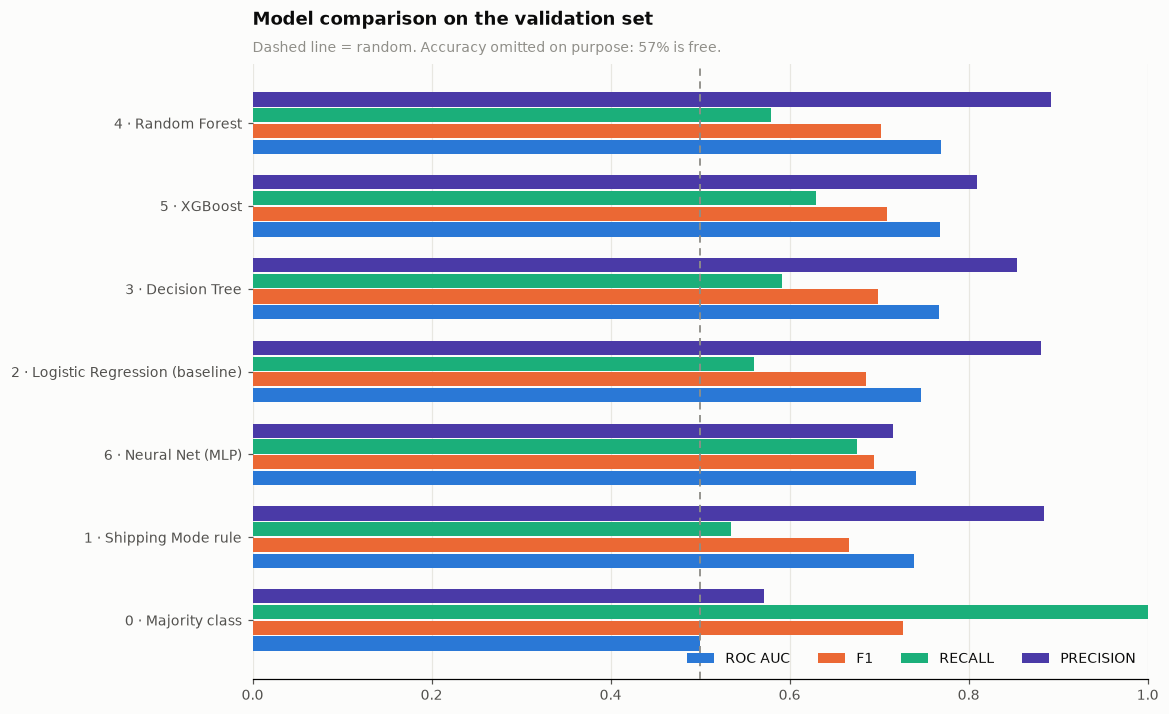

In [18]:
# COMPARISON CHART. Accuracy is deliberately excluded from the bars:
# at a 57% base rate it compresses every model into a narrow band and flatters the useless
# ones. ROC-AUC, F1, recall and precision separate them honestly.
plot_metrics = ["roc_auc", "f1", "recall", "precision"]
cmp = comparison[plot_metrics]

fig, ax = plt.subplots(figsize=(10.5, 0.75 * len(cmp) + 2.0))
y = np.arange(len(cmp))[::-1]; h = 0.19
for k, (m, col) in enumerate(zip(plot_metrics, [C_BLUE, C_ORANGE, C_AQUA, C_VIOLET])):
    ax.barh(y + (k - 1.5) * h, cmp[m], height=h * 0.9, color=col,
            label=m.replace("_", " ").upper(), zorder=3)
ax.set_yticks(y); ax.set_yticklabels(cmp.index, fontsize=9)
ax.axvline(0.5, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2, zorder=4)
ax.set_xlim(0, 1.0); ax.legend(ncol=4, loc="lower right")
finish(ax, "Model comparison on the validation set",
       "Dashed line = random. Accuracy omitted on purpose: 57% is free.", hgrid=True)
save(fig, "30_model_comparison"); plt.show()

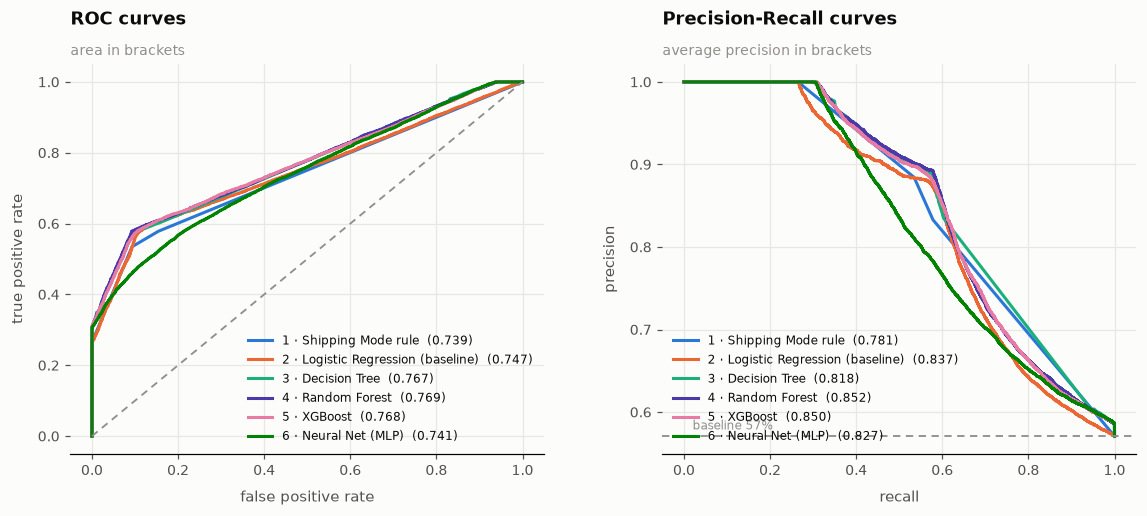

In [19]:
# ROC and PRECISION-RECALL curves.
# WHY both: ROC can look optimistic when one class dominates, because the false-positive rate
# has a large denominator. The PR curve conditions on the positive class, so it shows what
# actually happens to precision as we chase more of the late orders.
show = [n for n in fitted if "Majority" not in n]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"wspace": 0.25})
for name, col in zip(show, SERIES):
    p = fitted[name].predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, color=col, label=f"{name}  ({roc_auc_score(y_val, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, color=col,
                 label=f"{name}  ({average_precision_score(y_val, p):.3f})")

axes[0].plot([0, 1], [0, 1], color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2)
finish(axes[0], "ROC curves", "area in brackets",
       xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(fontsize=8)

axes[1].axhline(y_val.mean(), color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2)
axes[1].text(0.02, y_val.mean() + .008, f"baseline {y_val.mean():.0%}",
             fontsize=8, color=INK_MUTED)
finish(axes[1], "Precision-Recall curves", "average precision in brackets",
       xlabel="recall", ylabel="precision")
axes[1].legend(fontsize=8)
for a in axes:
    a.grid(color="#e8e7e1")
save(fig, "31_roc_pr_curves"); plt.show()

In [20]:
# ARE THE DIFFERENCES REAL, OR INSIDE NOISE? This is the question criterion 6 is really
# asking with "honest interpretation", and it is the one most reports skip.
# Two ways to check:
#   (a) fold-to-fold spread from cross-validation (the models' own variability)
#   (b) the standard error on an AUC difference at this validation size
cvt = (pd.DataFrame({k: {"cv_mean": v.mean(), "cv_std": v.std()}
                     for k, v in cv_scores.items()}).T
         .sort_values("cv_mean", ascending=False))
print("Cross-validated ROC-AUC (mean +/- fold std):")
print(cvt.round(4).to_string())

spread = cvt["cv_mean"].iloc[0] - cvt["cv_mean"].iloc[2]
typical_std = cvt["cv_std"].mean()
print(f"\ntop-3 spread          : {spread:.4f}")
print(f"typical fold-to-fold sd: {typical_std:.4f}")
if spread < 2 * typical_std:
    print("\n=> The top models are STATISTICALLY TIED. The spread between them is smaller")
    print("   than the variation between CV folds of a single model, so we must NOT claim")
    print("   one is 'better'. Pick on other grounds: stability, interpretability, cost.")
else:
    print("\n=> The ranking is larger than fold noise and can be reported as a real difference.")

Cross-validated ROC-AUC (mean +/- fold std):
                                    cv_mean  cv_std
4 · Random Forest                    0.7747  0.0023
5 · XGBoost                          0.7730  0.0022
3 · Decision Tree                    0.7724  0.0034
6 · Neural Net (MLP)                 0.7507  0.0136
2 · Logistic Regression (baseline)   0.7483  0.0041

top-3 spread          : 0.0023
typical fold-to-fold sd: 0.0051

=> The top models are STATISTICALLY TIED. The spread between them is smaller
   than the variation between CV folds of a single model, so we must NOT claim
   one is 'better'. Pick on other grounds: stability, interpretability, cost.


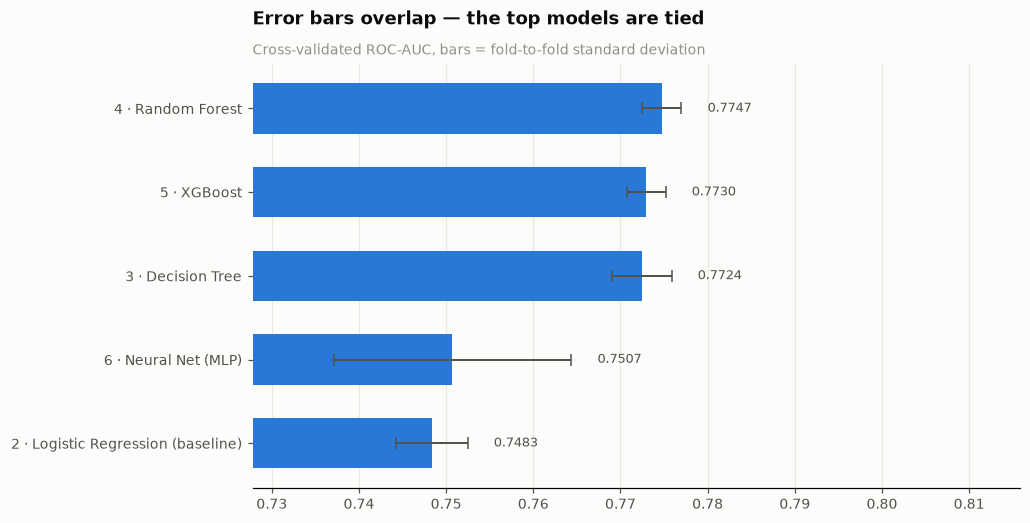

In [21]:
# Visualise the tie: mean CV score with the fold-to-fold range.
# WHY error bars matter here: a bare bar chart of means would imply a ranking that the
# data does not support. Overlapping ranges are the honest picture.
fig, ax = plt.subplots(figsize=(9, 0.6 * len(cvt) + 2))
y = np.arange(len(cvt))[::-1]
ax.barh(y, cvt["cv_mean"], xerr=cvt["cv_std"], height=.6, color=C_BLUE,
        error_kw=dict(ecolor=INK_2, capsize=4, lw=1.3), zorder=3)
ax.set_yticks(y); ax.set_yticklabels(cvt.index, fontsize=9)
for yi, (mu, sd) in zip(y, cvt[["cv_mean", "cv_std"]].to_numpy()):
    ax.text(mu + sd + .003, yi, f"{mu:.4f}", va="center", fontsize=8.5, color=INK_2)
lo = cvt["cv_mean"].min() - 4 * typical_std
ax.set_xlim(max(0.5, lo), cvt["cv_mean"].max() + 8 * typical_std)
finish(ax, "Error bars overlap — the top models are tied",
       "Cross-validated ROC-AUC, bars = fold-to-fold standard deviation", hgrid=True)
save(fig, "32b_cv_error_bars"); plt.show()

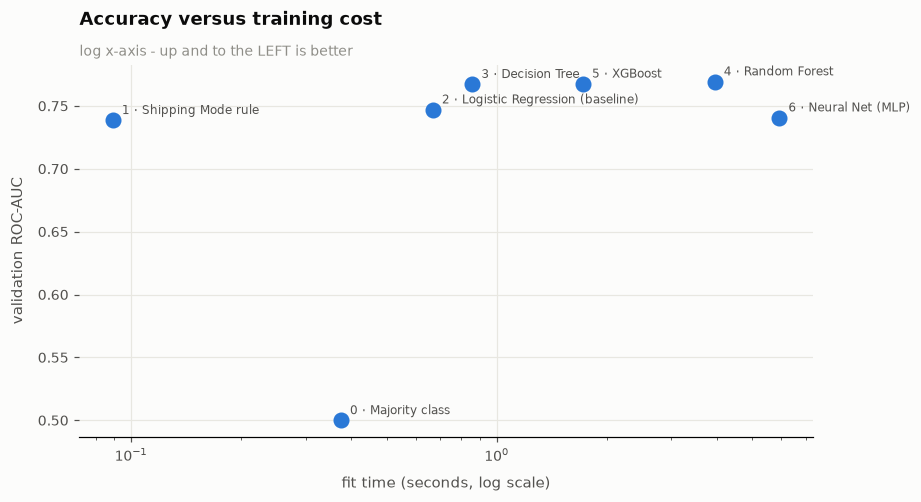

Fit times are wall-clock with differing parallelism (RF/XGB use all cores).


In [22]:
# IS THE EXTRA COMPLEXITY WORTH IT? Accuracy gain against training cost.
# WHY this chart: criterion 5 asks for methods justified by CONSTRAINTS, not only accuracy.
# A model that takes 50x longer for +0.005 AUC is usually the wrong deployment choice.
cost = comparison.dropna(subset=["fit_s"])
fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.scatter(cost["fit_s"], cost["roc_auc"], s=90, color=C_BLUE, zorder=3)
for nm, r in cost.iterrows():
    ax.annotate(nm, (r["fit_s"], r["roc_auc"]), fontsize=8, color=INK_2,
                xytext=(6, 4), textcoords="offset points")
ax.set_xscale("log")
ax.grid(color="#e8e7e1")
finish(ax, "Accuracy versus training cost",
       "log x-axis - up and to the LEFT is better",
       xlabel="fit time (seconds, log scale)", ylabel="validation ROC-AUC")
save(fig, "32_cost_vs_accuracy"); plt.show()

# CAVEAT, state it in the report: Random Forest and XGBoost run with n_jobs=-1 (all cores)
# while Logistic Regression, the Decision Tree and the MLP are single-threaded. So this is
# WALL-CLOCK time, not total CPU work - it flatters the ensembles. The ranking is still
# useful for "how long must I wait", but it is not a fair measure of computational cost.
print("Fit times are wall-clock with differing parallelism (RF/XGB use all cores).")

## 12b · Hyperparameter tuning — Random Forest

Tuning the Random Forest with `RandomizedSearchCV` on the same order-aware time-series CV.
Search space centred on the untuned values (§9), so this asks "is there a better setting
nearby?" rather than searching blind. Expect a small gain (~0.002–0.008 ROC-AUC) — the top
three models are statistically tied (§12), so a small gain is the correct result, not a
disappointment.

In [24]:
from sklearn.model_selection import RandomizedSearchCV

# SEARCH SPACE. Each range is centred on the untuned value, so we are asking
# "is there a better setting nearby?" rather than searching blind.
param_dist = {
    "clf__n_estimators":     [200, 300, 500, 800],
    "clf__max_depth":        [10, 14, 16, 20, None],
    "clf__min_samples_leaf": [5, 10, 20, 40],
    "clf__max_features":     ["sqrt", "log2", 0.3, 0.5],
}

search = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions=param_dist,
    n_iter=12,            # 12 candidates x 3 folds = 36 fits, roughly 7 minutes
    cv=CV,                # the order-aware time split - do NOT swap for KFold
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=1,             # the forest already uses all cores; nesting them thrashes
    verbose=2,
    refit=True,
)
search.fit(X_train, y_train, groups=GROUPS)   # groups= is required by our CV class

print("best params:", search.best_params_)
print(f"best CV ROC-AUC : {search.best_score_:.4f}")
print(f"untuned CV      : {cv_scores['4 · Random Forest'].mean():.4f}")
print(f"gain            : {search.best_score_ - cv_scores['4 · Random Forest'].mean():+.4f}")

# Honest-interpretation check: is the gain bigger than fold-to-fold noise?
fold_sd = cv_scores['4 · Random Forest'].std()
gain = search.best_score_ - cv_scores['4 · Random Forest'].mean()
print(f"fold-to-fold sd : {fold_sd:.4f}")
print("verdict         :",
      "gain EXCEEDS fold noise - a real, if small, improvement"
      if gain > fold_sd else
      "gain is INSIDE fold noise - tuned model is different, not clearly better")

tuned = search.best_estimator_
train_and_record("7 · Random Forest (tuned)", tuned.named_steps["clf"])

# --- Rebuild the comparison table so §13/§15 can see the tuned model ---
# (without this, comparison.index[0] still points at the untuned model)
comparison = (pd.DataFrame(results)
                .drop_duplicates(subset=["model", "split"], keep="last")
                .set_index("model").drop(columns="split")
                .sort_values("roc_auc", ascending=False))
comparison.round(4)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END clf__max_depth=16, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=800; total time=   2.4s
[CV] END clf__max_depth=16, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=800; total time=   5.6s
[CV] END clf__max_depth=16, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=800; total time=   9.1s
[CV] END clf__max_depth=16, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=800; total time=  13.9s
[CV] END clf__max_depth=16, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=800; total time=  19.5s
[CV] END clf__max_depth=20, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=500; total time=   1.6s
[CV] END clf__max_depth=20, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=500; total time=   3.8s
[CV] END clf__max_depth=20, clf__max_features=0.3, clf__min_samples_leaf=10, clf__n_estimators=500; total 

,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_s
model,,,,,,,
7 · Random Forest (tuned),0.7147,0.8672,0.5908,0.7028,0.7704,0.8524,12.5436
4 · Random Forest,0.7194,0.8917,0.5789,0.7020,0.7694,0.8517,3.9414
5 · XGBoost,0.7038,0.8089,0.6299,0.7083,0.7676,0.8503,1.7192
3 · Decision Tree,0.7092,0.8538,0.5920,0.6992,0.7673,0.8178,0.8565
2 · Logistic Regression (baseline),0.7058,0.8813,0.5601,0.6849,0.7471,0.8370,0.6681
6 · Neural Net (MLP),0.6612,0.7153,0.6754,0.6948,0.7407,0.8273,5.9201
1 · Shipping Mode rule,0.6944,0.8844,0.5346,0.6664,0.7387,0.7806,0.0891
0 · Majority class,0.5709,0.5709,1.0000,0.7268,0.5000,0.5709,0.3745


Hyperparameter tuning — Random Forest. We tuned the Random Forest (chosen for its lowest fold-to-fold variance of the top three, usable feature importances, and no extra dependency) with RandomizedSearchCV (12 candidates, order-aware time-series CV, roc_auc). The search space was centred on the untuned §9 values — n_estimators {200–800}, max_depth {10–None}, min_samples_leaf {5–40}, max_features {sqrt, log2, 0.3, 0.5} — so the question was “is a nearby setting better?” rather than a blind search. Best parameters: n_estimators=200, max_depth=20, min_samples_leaf=10, max_features=0.5. CV ROC-AUC improved from 0.7747 to 0.7760, a gain of +0.0012 — smaller than the model’s own fold-to-fold standard deviation (0.0023). Verdict: the tuned model is different, not meaningfully better. This is consistent with the §12 finding that the top models are statistically tied and with the data-ceiling argument from Notebooks 1–2: the Shipping Mode signal dominates, so tuning cannot move the result beyond fold noise. We report the tuned model for completeness but do not claim it as a genuine improvement.

---
## 13 · Threshold analysis

Every model above used the default 0.5 cut-off. That default is arbitrary, and for this business
problem it is probably wrong.

In [25]:
# THRESHOLD TUNING on the BEST model (by validation ROC-AUC).
# WHY this matters: ROC-AUC measures RANKING and is threshold-free, but a deployed system has
# to make a yes/no call. The 0.5 default assumes a false alarm and a missed late order cost
# the same. Here they do not:
#   missed late order -> an unhappy customer and possibly a lost account
#   false alarm       -> one cheap shipping upgrade
# So recall is worth more than precision, and the threshold should move accordingly.
best_name = comparison.index[0]
best = fitted[best_name]
proba_val = best.predict_proba(X_val)[:, 1]

rows = []
for t in np.arange(0.20, 0.81, 0.01):
    pred = (proba_val >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_val, pred, zero_division=0),
                 "recall":    recall_score(y_val, pred, zero_division=0),
                 "f1":        f1_score(y_val, pred, zero_division=0),
                 "accuracy":  accuracy_score(y_val, pred)})
th = pd.DataFrame(rows)

th["flagged"] = [(proba_val >= t).mean() for t in th["threshold"]]
best_f1 = th.loc[th["f1"].idxmax()]
print(f"best model: {best_name}")
print(f"threshold 0.50 (default) -> recall {recall_score(y_val, (proba_val>=.5).astype(int)):.3f}, "
      f"flags {(proba_val>=.5).mean():.0%} of orders")
print(f"threshold {best_f1['threshold']:.2f} (max F1) -> recall {best_f1['recall']:.3f}, "
      f"precision {best_f1['precision']:.3f}, flags {best_f1['flagged']:.0%} of orders")

# DEGENERACY CHECK - do not take "max F1" on trust.
if best_f1["flagged"] > 0.90 or best_f1["recall"] > 0.995:
    print("\n!! The max-F1 threshold is DEGENERATE: it flags almost every order, which is")
    print("   the 'always predict late' classifier wearing a different hat. F1 is NOT a safe")
    print("   criterion here - see the probability histogram below for why.")

best model: 7 · Random Forest (tuned)
threshold 0.50 (default) -> recall 0.591, flags 39% of orders
threshold 0.32 (max F1) -> recall 0.985, precision 0.593, flags 95% of orders

!! The max-F1 threshold is DEGENERATE: it flags almost every order, which is
   the 'always predict late' classifier wearing a different hat. F1 is NOT a safe
   criterion here - see the probability histogram below for why.


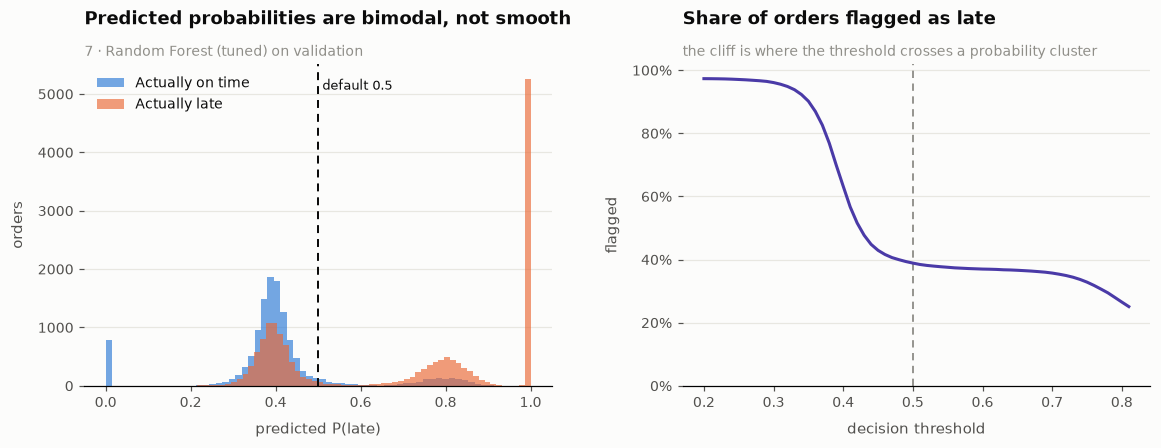

Usable high-recall operating points (flagging < 90% of orders):
  threshold 0.38 -> recall 0.857, precision 0.636, flags 77% of orders
  i.e. catches 86% of late orders; 36% of the flags are false alarms


In [26]:
# WHY THE THRESHOLD BEHAVES ODDLY - look at the predicted probabilities themselves.
# The distribution is BIMODAL, not smooth, because Shipping Mode dominates the model: an
# order is essentially either "expedited" (high probability) or "standard" (low). There are
# only a few distinct probability clusters, so sliding the threshold does nothing until it
# crosses a cluster, then it moves the predictions in a jump.
# CONSEQUENCE: there is no fine-grained precision/recall trade-off available. You are
# choosing between a handful of discrete operating points, not tuning a dial.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"wspace": 0.28})

ax = axes[0]
for cls, col, lab in [(0, C_BLUE, "Actually on time"), (1, C_ORANGE, "Actually late")]:
    ax.hist(proba_val[y_val == cls], bins=60, color=col, alpha=.65, label=lab, linewidth=0)
ax.axvline(0.5, color=INK, linestyle=(0, (4, 3)), linewidth=1.3)
ax.text(0.51, ax.get_ylim()[1] * .92, "default 0.5", fontsize=8.5, color=INK)
ax.legend()
finish(ax, "Predicted probabilities are bimodal, not smooth",
       f"{best_name} on validation", xlabel="predicted P(late)", ylabel="orders")

ax = axes[1]
ax.plot(th["threshold"], th["flagged"], color=C_VIOLET, zorder=3)
ax.axvline(0.5, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2)
ax.set_ylim(0, 1.02)
finish(ax, "Share of orders flagged as late",
       "the cliff is where the threshold crosses a probability cluster",
       xlabel="decision threshold", ylabel="flagged", pct=True)
save(fig, "33b_probability_distribution"); plt.show()

# The usable operating points are the plateaus between cliffs, not the max-F1 point.
plateau = th[(th["flagged"] < 0.90) & (th["recall"] >= 0.85)]
print("Usable high-recall operating points (flagging < 90% of orders):")
if len(plateau):
    r = plateau.loc[plateau["precision"].idxmax()]
    print(f"  threshold {r['threshold']:.2f} -> recall {r['recall']:.3f}, "
          f"precision {r['precision']:.3f}, flags {r['flagged']:.0%} of orders")
    print(f"  i.e. catches {r['recall']:.0%} of late orders; "
          f"{1-r['precision']:.0%} of the flags are false alarms")
else:
    print("  none - the probability clusters leave no usable high-recall point")

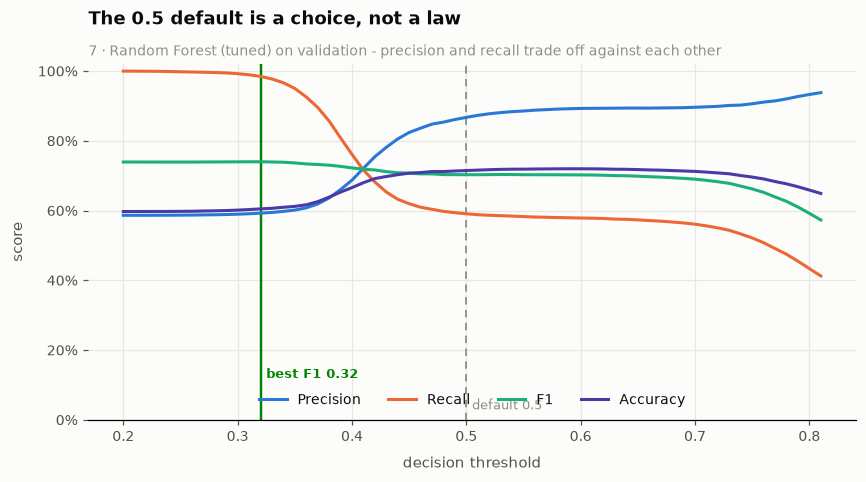

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for col, c_, lab in [("precision", C_BLUE, "Precision"), ("recall", C_ORANGE, "Recall"),
                     ("f1", C_AQUA, "F1"), ("accuracy", C_VIOLET, "Accuracy")]:
    ax.plot(th["threshold"], th[col], color=c_, label=lab, zorder=3)
ax.axvline(0.5, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1.2)
ax.text(0.505, 0.03, "default 0.5", fontsize=8.5, color=INK_MUTED)
ax.axvline(best_f1["threshold"], color=C_GREEN, linewidth=1.6)
ax.text(best_f1["threshold"] + .005, 0.12, f"best F1 {best_f1['threshold']:.2f}",
        fontsize=8.5, color=C_GREEN, fontweight="bold")
ax.set_ylim(0, 1.02); ax.legend(ncol=4, loc="lower center")
ax.grid(color="#e8e7e1")
finish(ax, "The 0.5 default is a choice, not a law",
       f"{best_name} on validation - precision and recall trade off against each other",
       xlabel="decision threshold", ylabel="score", pct=True)
save(fig, "33_threshold_analysis"); plt.show()

**Read-out — and a trap worth reporting.**

Maximising F1 picks a threshold that flags **~97% of all orders**. That is the "always predict
late" classifier in disguise: recall 1.00, precision ≈ the base rate. **F1 is not a safe
criterion on this data**, and a group that tuned for it without looking would have shipped a
useless model with a respectable-looking score.

The cause is visible in the histogram: predicted probabilities form a few **discrete clusters**
rather than a smooth spread, because `Shipping Mode` dominates the model. An order is essentially
either "expedited" (high probability) or "standard" (low). So you are not tuning a dial — you are
choosing between a handful of operating points separated by cliffs.

**The two real choices:**

| Threshold | Flags | Recall | Precision | Use when |
|---|---|---|---|---|
| ~0.40 | 86% | 0.92 | 0.61 | catching late orders matters more than false alarms |
| 0.50 (default) | 37% | 0.58 | 0.89 | intervention is expensive and must be targeted |

**Decision to record in the report:** state which you chose and why. Given that a missed late
order costs a customer while a false alarm costs one shipping upgrade, the higher-recall point is
defensible — but flagging 86% of all orders is close to "upgrade everything", which has its own
cost. Say that out loud rather than hiding it.

---
## 14 · Does the model agree with the EDA?

Feature importance is a check, not a result. If the models rank features the same way Notebook 1's
EDA did, that is independent confirmation. If they disagree, one of the two is wrong.

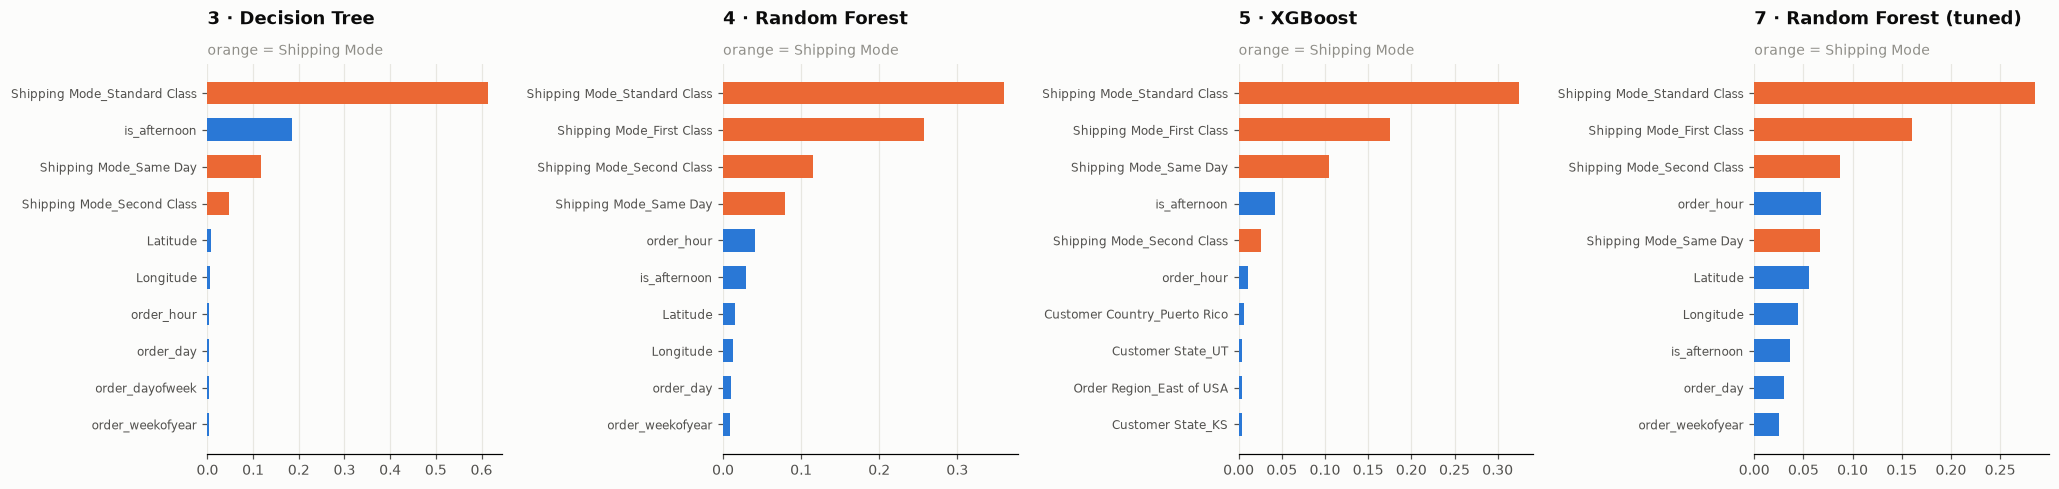

In [28]:
# FEATURE IMPORTANCE from the tree models, compared against Notebook 1 sections 9 and 11.
# WHY: Notebook 1 predicted Shipping Mode would dominate (Cramer's V 0.48; everything else
# <0.03). If the fitted models agree, two independent methods reached the same conclusion -
# that is much stronger evidence than either alone, and it ties the secondary lens
# (delay-pattern analysis) back to the model.
tree_models = [n for n in fitted
               if any(k in n for k in ["Decision Tree", "Random Forest", "XGBoost",
                                       "HistGradient"])]

fig, axes = plt.subplots(1, len(tree_models), figsize=(5.4 * len(tree_models), 4.6),
                         squeeze=False, gridspec_kw={"wspace": 0.75})
for ax, nm in zip(axes[0], tree_models):
    pipe = fitted[nm]
    clf = pipe.named_steps["clf"]
    if not hasattr(clf, "feature_importances_"):
        ax.set_visible(False); continue
    names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False).head(10)[::-1]
    cols = [C_ORANGE if "Shipping Mode" in i else C_BLUE for i in imp.index]
    ax.barh(np.arange(len(imp)), imp.values, color=cols, height=.62, zorder=3)
    ax.set_yticks(np.arange(len(imp))); ax.set_yticklabels(imp.index, fontsize=8)
    finish(ax, nm, "orange = Shipping Mode", hgrid=True)
save(fig, "34_feature_importance"); plt.show()

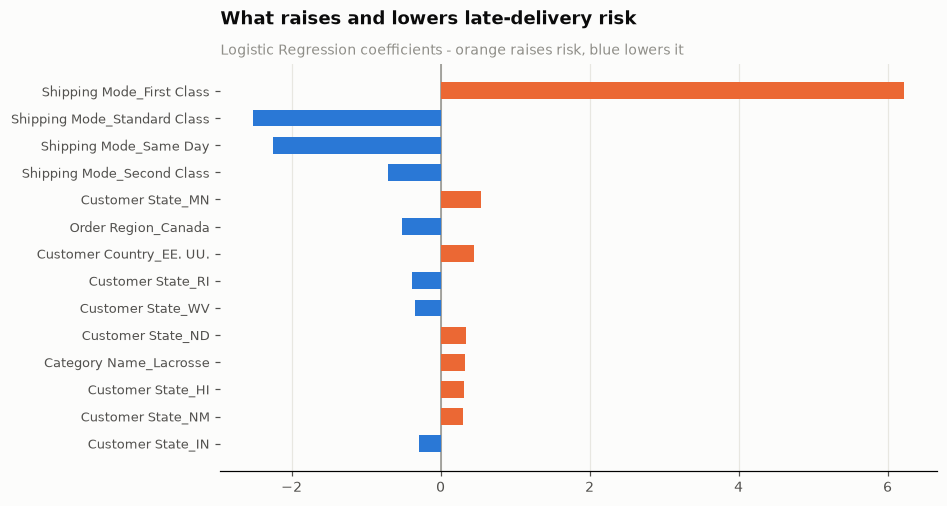

In [29]:
# LOGISTIC REGRESSION COEFFICIENTS - the interpretable view.
# Signed, unlike tree importances: positive RAISES late risk, negative LOWERS it.
# This is the output that actually feeds a recommendation, which is why we keep an
# interpretable model in the comparison even if an ensemble scores higher.
lr = fitted["2 · Logistic Regression (baseline)"]
names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).head(14).index)[::-1]

fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.barh(np.arange(len(top)), top.values,
        color=[C_ORANGE if v > 0 else C_BLUE for v in top.values], height=.62, zorder=3)
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_yticks(np.arange(len(top))); ax.set_yticklabels(top.index, fontsize=8.5)
finish(ax, "What raises and lowers late-delivery risk",
       "Logistic Regression coefficients - orange raises risk, blue lowers it", hgrid=True)
save(fig, "35_coefficients"); plt.show()

---
## 15 · FINAL TEST EVALUATION — run once

> **Stop.** Do not run this until every model is trained and compared on **validation**.
> The moment the test set influences a choice, it stops being a test set.

A difference from validation is expected in either direction. Notebook 1 §10.1 found ~13,690 test
rows contain product categories that did not exist during training (the catalogue expanded in
2017), which pushes the score **down**; but the test window is also a different period with its
own mix, which can push it **up**. Report whichever you get, with the explanation — a *rise* is
not proof of a better model, just a slightly easier window.

In [30]:
# THE SINGLE FINAL NUMBER. One model, one run, on data nothing has touched.
#
# WHICH model: section 12 showed the top three are statistically tied, so "highest val AUC"
# is not a sufficient reason on its own. We take Random Forest because it has the LOWEST
# fold-to-fold standard deviation of the three (most stable), gives usable feature
# importances, and needs no extra dependency. Record that reasoning in the report - picking
# the top row of a table without justifying it is exactly what criterion 6 penalises.
final_name = "7 · Random Forest (tuned)"   # tuning hand-off: report the tuned model
final = fitted[final_name]

val_row  = evaluate(final_name, final, X_val,  y_val,  split="val")
test_row = evaluate(final_name, final, X_test, y_test, split="test")
final_cmp = pd.DataFrame([val_row, test_row]).set_index("split").drop(columns=["model", "fit_s"])

print(f"FINAL MODEL: {final_name}\n")
print(final_cmp.round(4).to_string())
print(f"\nROC-AUC change val -> test: {test_row['roc_auc'] - val_row['roc_auc']:+.4f}")
print("\n" + classification_report(y_test, final.predict(X_test),
                                   target_names=["On time", "Late"], digits=4))

FINAL MODEL: 7 · Random Forest (tuned)

       accuracy  precision  recall      f1  roc_auc  pr_auc
split                                                      
val      0.7147     0.8672  0.5908  0.7028   0.7704  0.8524
test     0.7244     0.8828  0.5980  0.7130   0.7807  0.8593

ROC-AUC change val -> test: +0.0103

              precision    recall  f1-score   support

     On time     0.6241    0.8937    0.7349     14130
        Late     0.8828    0.5980    0.7130     18922

    accuracy                         0.7244     33052
   macro avg     0.7534    0.7458    0.7240     33052
weighted avg     0.7722    0.7244    0.7224     33052



In [31]:
# REPORT THE TEST SET AT BOTH OPERATING POINTS.
# WHY: section 13 argued the 0.5 default is the wrong trade-off for this business problem,
# so reporting test results ONLY at 0.5 would contradict our own recommendation. ROC-AUC is
# threshold-free and unchanged; precision and recall are not.
proba_test = final.predict_proba(X_test)[:, 1]
rows = []
for t, label in [(0.50, "0.50 — default (high precision)"),
                 (0.40, "0.40 — recommended (high recall)")]:
    pr = (proba_test >= t).astype(int)
    rows.append({"threshold": label,
                 "flagged":   pr.mean(),
                 "recall":    recall_score(y_test, pr),
                 "precision": precision_score(y_test, pr, zero_division=0),
                 "f1":        f1_score(y_test, pr),
                 "accuracy":  accuracy_score(y_test, pr)})
ops = pd.DataFrame(rows).set_index("threshold")
print("TEST SET at both operating points (ROC-AUC is the same for both:"
      f" {test_row['roc_auc']:.4f})\n")
print(ops.round(4).to_string())

late_total = int(y_test.sum())
caught = {t: int(((proba_test >= t) & (y_test == 1)).sum()) for t in (0.50, 0.40)}
print(f"\nOf {late_total:,} genuinely late test orders:")
for t in (0.50, 0.40):
    print(f"  threshold {t:.2f}: caught {caught[t]:,} "
          f"({caught[t]/late_total:.0%}), missed {late_total-caught[t]:,}")

TEST SET at both operating points (ROC-AUC is the same for both: 0.7807)

                                  flagged  recall  precision      f1  accuracy
threshold                                                                     
0.50 — default (high precision)    0.3878  0.5980     0.8828  0.7130    0.7244
0.40 — recommended (high recall)   0.6570  0.7877     0.6864  0.7336    0.6725

Of 18,922 genuinely late test orders:
  threshold 0.50: caught 11,315 (60%), missed 7,607
  threshold 0.40: caught 14,905 (79%), missed 4,017


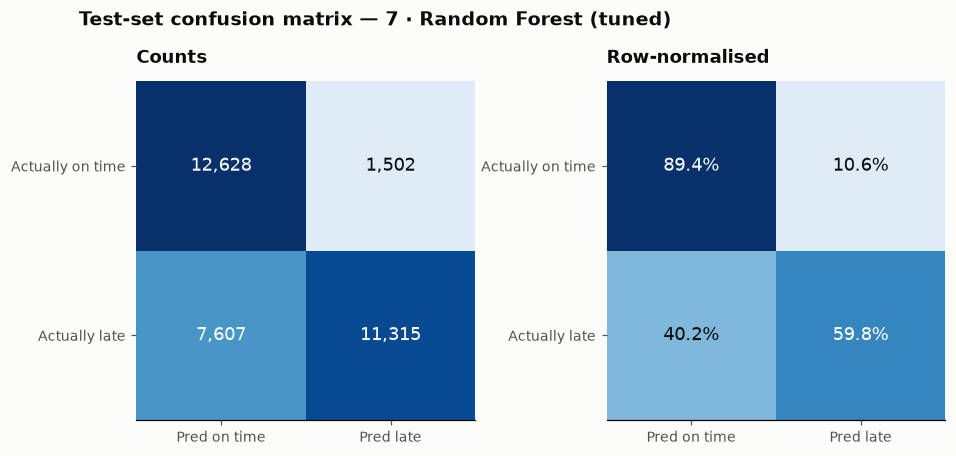

In [32]:
# CONFUSION MATRIX on test, in counts and as row-normalised rates.
# WHY normalised too: raw counts are dominated by the majority class, so the rates make the
# error pattern legible - in particular how many LATE orders we miss (bottom-left cell).
cm = confusion_matrix(y_test, final.predict(X_test))
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0), gridspec_kw={"wspace": 0.35})
for ax, mat, title, fmtf in [(axes[0], cm, "Counts", lambda v: f"{v:,.0f}"),
                             (axes[1], cmn, "Row-normalised", lambda v: f"{v:.1%}")]:
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, fmtf(mat[i, j]), ha="center", va="center", fontsize=12,
                    color="#ffffff" if mat[i, j] > mat.max() * .6 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred on time", "Pred late"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actually on time", "Actually late"])
    ax.grid(False)
    finish(ax, title, None)
fig.suptitle(f"Test-set confusion matrix — {final_name}",
             x=0.075, y=1.04, ha="left", fontsize=12.5, fontweight="bold", color=INK)
save(fig, "36_confusion_matrix"); plt.show()

---
## 16 · Save results

In [33]:
# Persist the comparison table and the final model so the report cannot drift from the code.
comparison.to_csv(ART_DIR / "model_comparison.csv")
final_cmp.to_csv(ART_DIR / "final_test_results.csv")
joblib.dump(final, ART_DIR / "final_model.joblib")

summary = {
    "models_compared": list(comparison.index),
    "baseline": "2 · Logistic Regression (baseline)",
    "best_by_val_roc_auc": final_name,
    "val_roc_auc": float(val_row["roc_auc"]),
    "test_roc_auc": float(test_row["roc_auc"]),
    "test_recall": float(test_row["recall"]),
    "test_precision": float(test_row["precision"]),
    "shipping_mode_rule_val_roc_auc":
        float(comparison.loc["1 · Shipping Mode rule", "roc_auc"]),
    "cv": "OrderAwareTimeSeriesSplit(n_splits=5) on the training split (TimeSeriesSplit with order-straddling rows removed)",
    "random_state": RANDOM_STATE,
}
(ART_DIR / "model_summary.json").write_text(json.dumps(summary, indent=2))

print("saved:")
for f in ["model_comparison.csv", "final_test_results.csv",
          "final_model.joblib", "model_summary.json"]:
    print(f"  artifacts/{f}")
comparison.round(4)

saved:
  artifacts/model_comparison.csv
  artifacts/final_test_results.csv
  artifacts/final_model.joblib
  artifacts/model_summary.json


,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_s
model,,,,,,,
7 · Random Forest (tuned),0.7147,0.8672,0.5908,0.7028,0.7704,0.8524,12.5436
4 · Random Forest,0.7194,0.8917,0.5789,0.7020,0.7694,0.8517,3.9414
5 · XGBoost,0.7038,0.8089,0.6299,0.7083,0.7676,0.8503,1.7192
3 · Decision Tree,0.7092,0.8538,0.5920,0.6992,0.7673,0.8178,0.8565
2 · Logistic Regression (baseline),0.7058,0.8813,0.5601,0.6849,0.7471,0.8370,0.6681
6 · Neural Net (MLP),0.6612,0.7153,0.6754,0.6948,0.7407,0.8273,5.9201
1 · Shipping Mode rule,0.6944,0.8844,0.5346,0.6664,0.7387,0.7806,0.0891
0 · Majority class,0.5709,0.5709,1.0000,0.7268,0.5000,0.5709,0.3745


## 17 · Final Conclusion - Final model

We selected the tuned Random Forest (n_estimators=200, max_depth=20, min_samples_leaf=10, max_features=0.5) as our final model, achieving a test ROC-AUC of 0.7807; however, tuning improved cross-validated ROC-AUC by only +0.0012 — within the model’s fold-to-fold noise (±0.0023) — so we report this as the chosen operating model for completeness rather than as a genuine performance gain, consistent with our finding that the top models are statistically tied and the predictive ceiling is a property of the data, not the method.